# Segmentation

A segmenter splits an image into masks, one per object or region. Masks clean up patch
features: averaging the features inside each mask gives one clear feature per object. This page
runs MobileSAM on the first keyframe, pools Talk2DINO features in its masks, The lifting and query page
lifts the masks of every keyframe to 3D.

In [1]:
import contextlib
import io

import matplotlib.pyplot as plt
import transformers

from collab_splats.semantics import (
    MobileSAMSegmentation,
    Talk2DinoExtractor,
    aggregate_masked_features,
)
from collab_splats.utils.visualization import overlay_masks, pca_to_rgb

%run ../tutorial.py

# Hide a harmless checkpoint warning from Talk2DINO
transformers.logging.set_verbosity_error()

# Image panels without axes
BARE = {"frame_on": False, "xticks": [], "yticks": []}

# The scene's first keyframe, the frame every semantics page shows
scene = tutorial_scene("preproc", "pointcloud")
frame = first_keyframe(scene)

## 1. Two ways to prompt SAM

- `object`: a detector finds objects, then SAM draws one mask per object, down to small litter.
- `auto`: SAM is prompted with a grid of points, so it can also mask large regions.

Segment the frame both ways:

object: 61 masks


auto: 43 masks


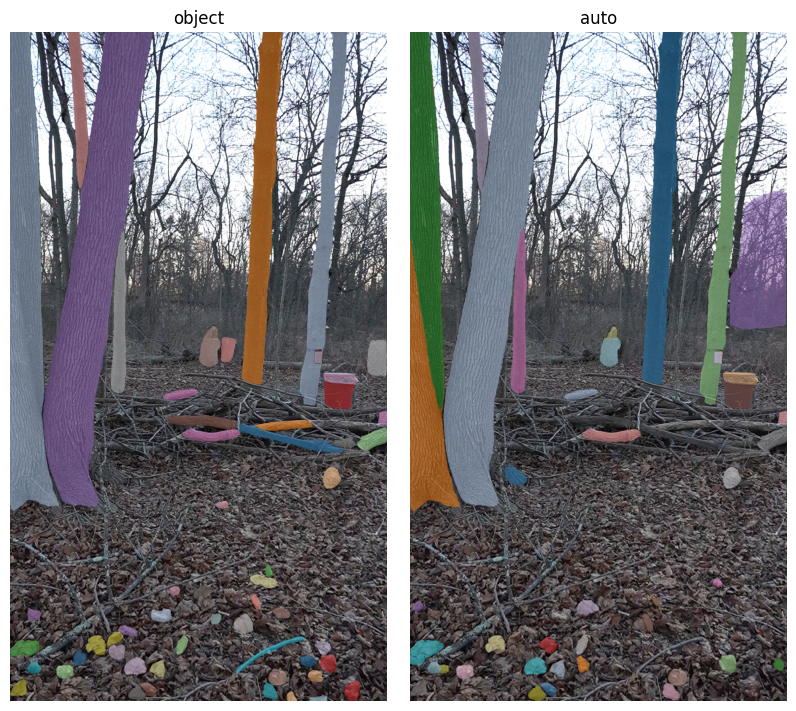

In [2]:
masks = {}

for strategy in ("object", "auto"):
    # Hide model-loading output
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        segmenter = MobileSAMSegmentation(strategy=strategy, device="cuda")
        masks[strategy], _ = segmenter.segment(frame)

    print(f"{strategy}: {len(masks[strategy])} masks")

fig, axes = plt.subplots(1, 2, figsize=(8, 7), subplot_kw=BARE, layout="constrained")

for ax, strategy in zip(axes, masks):
    ax.imshow(overlay_masks(frame, masks[strategy]))
    ax.set_title(strategy)

Each color is one mask. Both cover trunks, logs and small items; `object` finds more of the
small litter. On this frame neither masks the ground or the sky.

## 2. Pooling features per mask

`aggregate_masked_features` averages the features inside each mask and paints the average back
over the mask. Where masks overlap, the later one wins; pixels in no mask get zero.

Pool Talk2DINO features in the `object` masks:

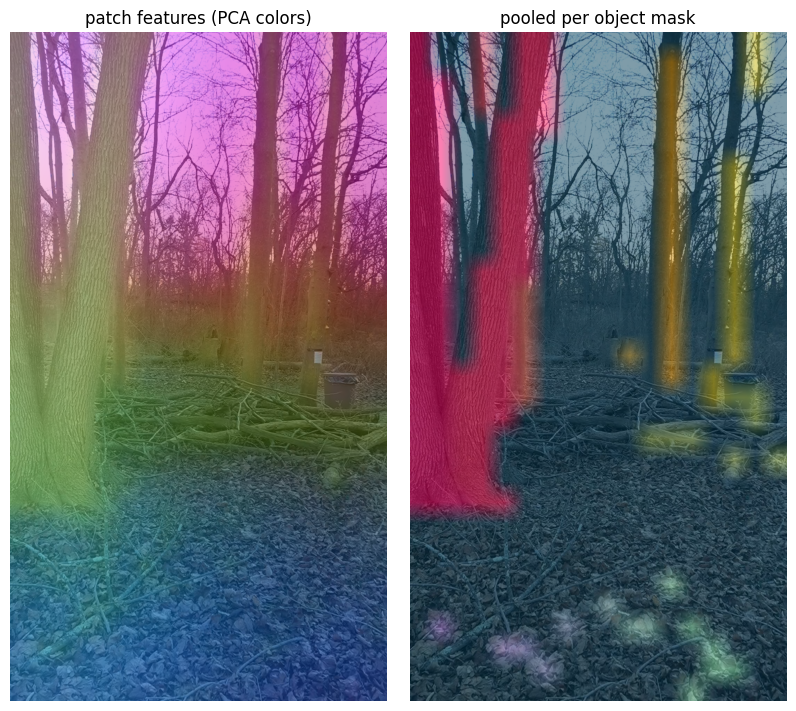

In [3]:
features = Talk2DinoExtractor().forward([frame])[0]
patch_grid = tuple(features.shape[1:])
pooled = aggregate_masked_features(
    features, masks["object"], resolution=patch_grid, final_resolution=patch_grid
)

panels = {"patch features (PCA colors)": features, "pooled per object mask": pooled}
fig, axes = plt.subplots(1, 2, figsize=(8, 7), subplot_kw=BARE, layout="constrained")

for ax, (title, fmap) in zip(axes, panels.items()):
    ax.imshow(pca_to_rgb(fmap, frame))
    ax.set_title(title)

Similar colors mean similar features. On the left, colors vary patch by patch within an object;
on the right, each object is one flat color.

## In a pipeline run

With `segments` on (off by default), the `semantics` stage segments every keyframe and lifts the
masks to 3D groups; see the lifting and query page. The mesh stage segments too: it removes the
sky before fusing depth; see the mesh page.

```yaml
semantics:
  segments:
    enabled: true
    strategy: object     # object (YOLOv8 boxes) | auto (grid, ~35x slower)
mesh:
  mask_sky: true         # the default
```